**This notebook implements and analyses risk-based allocation strategies on the Euro Stoxx 50 universe with monthly rebalancing and a 2-year rolling estimation window**

**Outline** 

0. Setup & rolling estimators
1. Part I — Equal Risk Contribution (ERC)
2. Part II — Hierarchical Risk Parity (HRP):
   1. Detoning intuition
   2. Cluster stability across rebalances (Rand index)
   3. Sensitivity to clustering choice and to the volatility allocation scheme
3. Part III — Connecting the dots: ERC vs HRP head-to-head and the role of shrinkage


## 0. Setup


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.metrics import rand_score

from utilities.backtest import backtest, portfolio_returns
from utilities.covariance_utilities import (
    prepare_rolling_estimation_window,
    covariance_to_correlation,
    risk_contribution,
)

from utilities.hierarchical_clustering import hierarchical_clustering

from utilities.hierarchical_risk_parity import (
    correlation_to_hrp_distance,
    dendrogram_iteration,
    hierarchical_risk_parity,
    recursive_bisection,
)

from utilities.portfolio_optimization import (
    equal_risk_contribution_portfolio,
    inverse_volatility_portfolio,
)

from utilities.principal_component_analysis import (
    detone,
    principal_component_analysis,
)

from utilities.shrinkage import constant_corr_shrinkage, market_factor_shrinkage


In [3]:
# Read prices, compute daily simple returns
data_path = Path("data")
last_prices = pd.read_csv(
    data_path / "sx5e_underlyings.csv", index_col="Date", parse_dates=True
)

performance = last_prices.pct_change().iloc[1:]
performance.head()

C:\Users\user\AppData\Local\Temp\ipykernel_18876\150134679.py:7: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  performance = last_prices.pct_change().iloc[1:]


,ABI.BR,AD.AS,ADSGn.DE,ADYEN.AS,AIR.PA,AIRP.PA,ALVG.DE,ASML.AS,AXAF.PA,BASFn.DE,...,SAN.MC,SAPG.DE,SASY.PA,SCHN.PA,SGEF.PA,SIEGn.DE,STLAM.MI,TTEF.PA,VNAn.DE,VOWG_p.DE
Date,,,,,,,,,,,,,,,,,,,,,
2013-01-03,-0.012027,0.000000,-0.004446,NaN,0.004490,-0.006874,-0.002770,0.003388,0.001086,-0.011342,...,-0.003476,-0.001289,-0.002603,-0.004234,0.004343,0.000716,0.014396,-0.003002,NaN,-0.000559
2013-01-04,0.016231,0.011645,-0.006847,NaN,0.019868,0.001049,0.001852,-0.011621,0.002893,0.001659,...,0.003647,-0.008548,0.011812,-0.000354,0.003243,0.000835,0.016219,-0.000878,NaN,-0.000279
2013-01-07,-0.010204,0.006235,-0.006595,NaN,-0.001623,-0.008277,-0.004621,-0.020199,0.002885,-0.011453,...,-0.001264,-0.008459,-0.003936,-0.005848,-0.009564,-0.003694,0.000998,-0.016700,NaN,-0.016215
2013-01-08,-0.015389,-0.006673,0.001207,NaN,0.005691,-0.003275,-0.006035,-0.010872,-0.023732,-0.006979,...,0.002847,-0.004922,0.005042,0.000357,-0.002720,-0.006697,-0.012456,0.005874,NaN,-0.011083
2013-01-09,-0.018816,-0.005278,0.013261,NaN,0.038804,-0.002650,-0.018216,0.012650,0.005525,0.003795,...,0.009621,0.006101,0.001492,0.001426,0.011864,0.002047,0.019173,0.003682,NaN,-0.013793


In [ ]:
# Estimation parameters
estimation_window = 2*252  # two trading years of data window
min_coverage = 0.95  # asset must have >=95% non-NaN in the window
trading_days = 252

# Rebalance on the last trading day of each month
rebalance_dates = pd.DatetimeIndex(
    performance.groupby(pd.Grouper(freq="ME"))     # every date is grouped by month, and then each group is defined via the last day of the month
    .apply(lambda x: x.index[-1] if len(x) > 0 else None) #we actually take the last trading day
    .dropna()
    .values
)

rebalance_dates[:5]

DatetimeIndex(['2013-01-31', '2013-02-28', '2013-03-28', '2013-04-30',
               '2013-05-31'],
              dtype='datetime64[ns]', freq=None)

## 1. Pre-computation: rolling covariance estimators

For each rebalance date we estimate three covariance matrices on the trailing 2-year window:

- **sample** — plain `cov()`,
- **constant_corr** — Ledoit–Wolf (2003) constant-correlation shrinkage,
- **mkt_factor** — Ledoit–Wolf (2002) single-factor shrinkage with the
  equally-weighted return of the surviving universe used as the market
  proxy.

The asset universe at every rebalance is restricted to names with
≥95% non-missing observations in the window.


In [5]:
covariances = {}  # date -> {estimator_name: cov_df}
universes = {}  # date -> [tickers]

for rebalance_date in rebalance_dates:
    cur_returns, diag = prepare_rolling_estimation_window(
        returns=performance,
        rebalance_date=rebalance_date,
        lookback=estimation_window,
        min_coverage=min_coverage,
        return_diagnostics=True,
    )
    if diag["row_count"] < estimation_window or cur_returns.shape[1] == 0:
        continue

    reb = rebalance_date.to_pydatetime().date()
    universes[reb] = list(cur_returns.columns)

    sample_cov = cur_returns.cov()
    constant_corr_cov = constant_corr_shrinkage(cur_returns)["shrunk_cov"]
    market_proxy = cur_returns.mean(axis=1)
    mkt_factor_cov = market_factor_shrinkage(cur_returns, market_proxy)["shrunk_cov"]

    covariances[reb] = {
        "sample": sample_cov,
        "constant_corr": constant_corr_cov,
        "mkt_factor": mkt_factor_cov,
    }

all_dates = sorted(covariances.keys())

## Equal Risk Contribution (ERC)


### Sanity check: Risk contribution dispersion & IV ≡ ERC under a diagonal Σ


In [ ]:
iv_erc_delta = {}
erc_normalized_range = {}
for date in all_dates:
    sample_cov = covariances[date]["sample"].values
    
    # Evaluate the dispersion of risk contributions on the real sample covariance
    erc_weights = equal_risk_contribution_portfolio(sample_cov)
    erc_rc = risk_contribution(erc_weights.reshape(1, -1), sample_cov).flatten()
    
    # Calculate normalized range (should be very close to 0 if optimizer converged)
    erc_normalized_range[date] = (
        erc_rc.max() - erc_rc.min()
    ) / np.sum(erc_rc)

    # Verify IV == ERC under a diagonal covariance matrix
    diagonal_cov = np.diag(np.diag(sample_cov))
    iv_weights_diag = inverse_volatility_portfolio(diagonal_cov)
    erc_weights_diag = equal_risk_contribution_portfolio(diagonal_cov)
    
    # Now iv_erc_delta should effectively be 0
    iv_erc_delta[date] = np.linalg.norm(iv_weights_diag - erc_weights_diag, ord=1)

print("--- Sanity Check Results ---")
print(f"Average IV-ERC L1 Delta (Diagonal Sigma): {np.mean(list(iv_erc_delta.values())):.2e}")
print(f"Average ERC Risk Contribution Dispersion: {np.mean(list(erc_normalized_range.values())):.2e}")

--- Part 1.b Sanity Check Results ---
Average IV-ERC L1 Delta (Diagonal Sigma): 0.00e+00
Average ERC Risk Contribution Dispersion: 1.59e-02


### ERC backtest across the three covariance estimators


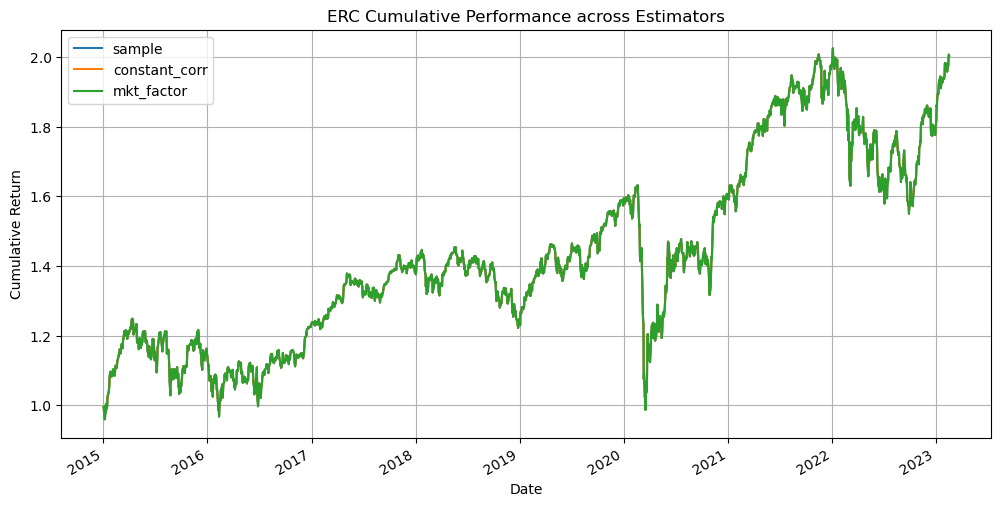

--- Part 1.c ERC Performance Summary ---
               Total Return  Avg 63d EWM Vol  Max Drawdown  \
sample             1.002795          0.17674     -0.395037   
constant_corr      1.002795          0.17674     -0.395037   
mkt_factor         1.002795          0.17674     -0.395037   

               Avg Monthly Turnover  
sample                     0.013934  
constant_corr              0.013934  
mkt_factor                 0.013934  


In [ ]:
erc_portfolios = {"sample": {}, "constant_corr": {}, "mkt_factor": {}}

# for each date in rebalance, we build the erc ptf as a series (asset, weight)
for reb in all_dates:
    for est_name, cov in covariances[reb].items():
        #COMMENT: each cov[reb].value is a DataFrame (a estimated covariance, which is a DataFrame in Pandas)
        erc_portfolios[est_name][reb] = pd.Series(
            equal_risk_contribution_portfolio(cov.values),
            index=cov.index, #so each weight is labelled with the asset (via an index)
            name=reb, #generci name of the Series
        )

#we build a DataFrame wehere for each data (index) we have all the weights for all the assets in the market
for est_name in erc_portfolios:
    # Get the universe (assets) for each rebalance date to align properly
    portfolio_list = []
    for reb, series in sorted(erc_portfolios[est_name].items()):
        # Align each series to the full performance.columns, filling missing with 0
        aligned = series.reindex(performance.columns, fill_value=0.0)
        portfolio_list.append(aligned)
    # Stack into DataFrame with rebalance dates as rows
    erc_portfolios[est_name] = pd.DataFrame(portfolio_list, index=sorted(erc_portfolios[est_name].keys()))

erc_backtests = {
    est_name: backtest(portfolios, performance)
    for est_name, portfolios in erc_portfolios.items()
}

erc_backtests = pd.DataFrame(erc_backtests)

plt.figure(figsize=(12, 6))
erc_backtests.plot(ax=plt.gca())
plt.title("ERC Cumulative Performance across Estimators")
plt.ylabel("Cumulative Return")
plt.grid(True)
plt.show()

summary_stats = pd.DataFrame(index=erc_backtests.columns)

# Cumulative Return
summary_stats['Total Return'] = erc_backtests.iloc[-1] - 1

# 63d EWM Volatility (Annualized)
# Note: we use returns here, not the cumulative backtest
returns_df = erc_backtests.pct_change()
ann_factor = np.sqrt(252)
summary_stats['Avg 63d EWM Vol'] = returns_df.ewm(span=63).std().mean() * ann_factor

# Maximum Drawdown
rolling_max = erc_backtests.cummax()
drawdowns = (erc_backtests - rolling_max) / rolling_max
summary_stats['Max Drawdown'] = drawdowns.min()

# Average Turnover
# Computed from the weight dataframes created in Cell 7
for est_name in erc_portfolios:
    weights = erc_portfolios[est_name]
    turnover = weights.diff().abs().sum(axis=1).mean()
    summary_stats.loc[est_name, 'Avg Monthly Turnover'] = turnover

print("--- ERC Performance Summary ---")
print(summary_stats)

In [8]:
# DEBUG: Check shrinkage targets and how they differ from sample
print("=== DEBUGGING: Shrinkage Targets ===")
first_date = all_dates[0]

# Get the returns for first rebalance date
cur_returns, _ = prepare_rolling_estimation_window(
    returns=performance,
    rebalance_date=pd.Timestamp(first_date),
    lookback=estimation_window,
    min_coverage=min_coverage,
    return_diagnostics=True,
)

sample_cov = cur_returns.cov().values
N = sample_cov.shape[0]

# Extract correlations
sample_std = np.sqrt(np.diag(sample_cov))
sample_outer = np.outer(sample_std, sample_std)
sample_corr = sample_cov / sample_outer

cc_result = constant_corr_shrinkage(cur_returns)
print(f"\n--- Constant Corr Shrinkage ---")
print(f"Intensity: {cc_result['intensity']:.6f}")
cc_target = cc_result['target'].values
cc_corr = cc_target / np.outer(np.sqrt(np.diag(cc_target)), np.sqrt(np.diag(cc_target)))
cc_shrunk = cc_result['shrunk_cov'].values

# Compute average correlation
avg_sample_corr = (np.sum(sample_corr) - N) / (N * (N - 1))
avg_cc_corr = (np.sum(cc_corr) - N) / (N * (N - 1))
print(f"Sample avg correlation: {avg_sample_corr:.6f}")
print(f"CC Target avg correlation: {avg_cc_corr:.6f}")
print(f"Sample vs CC Target Max Diff: {np.max(np.abs(sample_cov - cc_target)):.6f}")
print(f"Sample vs CC Shrunk Max Diff: {np.max(np.abs(sample_cov - cc_shrunk)):.6f}")

market_proxy = cur_returns.mean(axis=1)
mf_result = market_factor_shrinkage(cur_returns, market_proxy)
print(f"\n--- Market Factor Shrinkage ---")
print(f"Intensity: {mf_result['intensity']:.6f}")
mf_target = mf_result['target'].values
mf_shrunk = mf_result['shrunk_cov'].values

# Compute betas and residuals
mkt_var = market_proxy.var()
betas = np.array([cur_returns[col].cov(market_proxy) / mkt_var for col in cur_returns.columns])
residual_vars = cur_returns.var().values - mkt_var * betas**2
print(f"Market Variance: {mkt_var:.6f}")
print(f"Avg Beta: {betas.mean():.6f}")
print(f"Avg Residual Var: {residual_vars.mean():.6f}")
print(f"Sample vs MF Target Max Diff: {np.max(np.abs(sample_cov - mf_target)):.6f}")
print(f"Sample vs MF Shrunk Max Diff: {np.max(np.abs(sample_cov - mf_shrunk)):.6f}")

print(f"\n--- Between Targets ---")
print(f"CC Target vs MF Target Max Diff: {np.max(np.abs(cc_target - mf_target)):.6f}")

print(f"\n--- Between Shrunk Covs ---")
print(f"CC Shrunk vs MF Shrunk Max Diff: {np.max(np.abs(cc_shrunk - mf_shrunk)):.6f}")

=== DEBUGGING: Shrinkage Targets ===

--- Constant Corr Shrinkage ---
Intensity: 0.064552
Sample avg correlation: 0.424693
CC Target avg correlation: 0.424693
Sample vs CC Target Max Diff: 0.000155
Sample vs CC Shrunk Max Diff: 0.000010

--- Market Factor Shrinkage ---
Intensity: 0.213346
Market Variance: 0.000093
Avg Beta: 1.000000
Avg Residual Var: 0.000127
Sample vs MF Target Max Diff: 0.000085
Sample vs MF Shrunk Max Diff: 0.000018

--- Between Targets ---
CC Target vs MF Target Max Diff: 0.000150

--- Between Shrunk Covs ---
CC Shrunk vs MF Shrunk Max Diff: 0.000010


## Hierarchical Risk Parity (HRP)


### Detoning — intuition
Why we do that?

Basically, in a nutshell, all the assets in the universe will share some common factors, and this can be explained without the use of Heavy Math or Deep Financial Theory:
Imagine Kinder and Milka, they are both chocoloate producers, meaning that if the price of chocolate skyrockets or fall terribly, they will do the same! So, as said, they share something call "systematic factors/risk".

In a more complex way we can extend this reasoning to the whole general market: a Bearish market will affect negatively the whole universe (or a Bullish the opposite), indipendently by how much each asset is linked to the others; the market goes bad and won't be a cool diversified ptf to save you, since, even if in an independent way, everything is sinking!

==> Detoning = Removing this common factors from our Correlation (or Covariance) Matrix!!!

So we are removing using PCA (statistical method) the common factors, in order to have a more "objective" correlation matrix to deal with! In this sense, we can get much more informative metrics!

CONS: Detoned Matrix is by construction singula, so non invertible
PROS: we will neve invert it, since we will use it just to Cluster the assets

### Cluster stability across rebalances (Rand index)

We measure how stable the clustering is between consecutive rebalances via the Rand index. A value close to 1 means the partition into $k$ clusters changes little month-to-month.


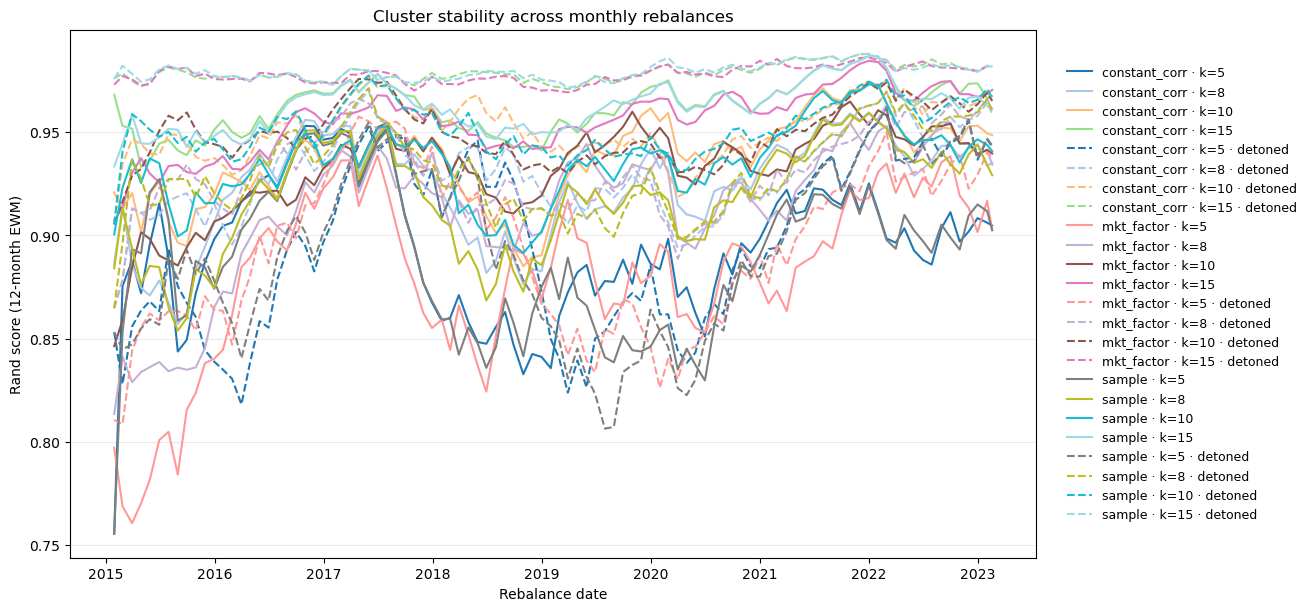

In [ ]:
from sklearn.metrics.cluster import rand_score

LINKAGE_METHOD = "ward"
DIST_METRIC = "euclidean"
N_CLUSTERS_GRID = [5, 8, 10, 15]
N_CLUSTERS_FOCUS = 10
COV_KEYS = ["sample", "constant_corr", "mkt_factor"]
DETONE_KEYS = [False, True]


linkages = {(c, d): {} for c in COV_KEYS for d in DETONE_KEYS}
clusters = {
    (c, d, k): {} for c in COV_KEYS for d in DETONE_KEYS for k in N_CLUSTERS_GRID
}


for reb in all_dates:
    for cov_key in COV_KEYS:
        cov = covariances[reb][cov_key]
        for detone_flag in DETONE_KEYS:
            if detone_flag == True:
                link = hierarchical_clustering(detone(cov), LINKAGE_METHOD, DIST_METRIC)
            else:
                link = hierarchical_clustering(cov, LINKAGE_METHOD, DIST_METRIC)
            for n_clusters in N_CLUSTERS_GRID:
                clusters[(cov_key, detone_flag, n_clusters)][reb] = pd.Series(
                    sch.cut_tree(link.values, n_clusters=n_clusters).flatten(),
                    index=cov.index,
                )

clusters_rand_scores = {
    (c, d, k): [] for c in COV_KEYS for d in DETONE_KEYS for k in N_CLUSTERS_GRID
}

for config in clusters:
    scores = []
    for i in range(1, len(all_dates)):
        current_date = all_dates[i]
        previous_date = all_dates[i-1]
        current = clusters[config][current_date]
        previous = clusters[config][previous_date]
        common_assets = current.index.intersection(previous.index)

        # The universe of assets in the cov changes over time!
        # In this way we select only the common assets!
        scores.append(rand_score(current[common_assets], previous[common_assets]))
    clusters_rand_scores[config] = pd.Series(scores, index=sorted(all_dates[1:])).ewm(span=12).mean()


# Plotting Rand Scores
groups = sorted({(cov_key, k) for cov_key, _, k in clusters_rand_scores})
palette = plt.get_cmap("tab20", len(groups))
colors = {group: palette(i) for i, group in enumerate(groups)}

fig, ax = plt.subplots(figsize=(13, 6), layout="constrained")

for (cov_key, detoned, k), scores in sorted(clusters_rand_scores.items()):
    ax.plot(
        scores.index,
        scores,
        color=colors[cov_key, k],
        linestyle="--" if detoned else "-",
        linewidth=1.5,
        label=f"{cov_key} · k={k}" + (" · detoned" if detoned else ""),
    )

ax.set(
    title="Cluster stability across monthly rebalances",
    xlabel="Rebalance date",
    ylabel="Rand score (12-month EWM)",
)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=9)

plt.show()


### Sensitivity of HRP weights — clustering vs. allocation traversal


In [12]:
LINK_GRID = ["single", "ward", "complete", "average"]
ALLOC_GRID = {
    "recursive_bisection": recursive_bisection,
    "dendrogram_iteration": dendrogram_iteration,
}

hrp_grid = {}
for reb in all_dates:
    for cov_key in COV_KEYS:
        cov = covariances[reb][cov_key]
        for link in LINK_GRID:
            for alloc_name, alloc in ALLOC_GRID.items():
                for d in DETONE_KEYS:
                        config = (cov_key, link, alloc_name, d)
                        hrp_grid.setdefault(config, {})[reb] = (
                            hierarchical_risk_parity(cov, link, DIST_METRIC, alloc, perform_detoning=d)
                        )

#As previuosly, we build for each config a DataFrame with all the weights at each rebalance date
for config in hrp_grid:
    portfolio_list = []
    for reb, series in sorted(hrp_grid[config].items()):
        aligned = series.reindex(performance.columns, fill_value=0.0)
        portfolio_list.append(aligned)
    hrp_grid[config] = pd.DataFrame(portfolio_list, index=sorted(hrp_grid[config].keys()))

for config in hrp_grid:
    weights = hrp_grid[config]
    turnover = weights.diff().abs().sum(axis=1).mean()
    print(f"Average Turnover for {config} is {turnover: .2%}")


c:\Users\user\Desktop\PoliMi_Dispense\MSc_QF\FinEng\Assignement\RM_Labs\Assignment_5\utilities\hierarchical_clustering.py:30: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage_matrix = sch.linkage(
c:\Users\user\Desktop\PoliMi_Dispense\MSc_QF\FinEng\Assignement\RM_Labs\Assignment_5\utilities\hierarchical_clustering.py:30: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage_matrix = sch.linkage(
c:\Users\user\Desktop\PoliMi_Dispense\MSc_QF\FinEng\Assignement\RM_Labs\Assignment_5\utilities\hierarchical_clustering.py:30: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage_matrix = sch.linkage(
c:\Users\user\Desktop\PoliMi_Dispense\MSc_QF\FinEng\Assignement\RM_Labs\Assignment_5\utilities\hierarchical_clustering.py:30: ClusterWarning: The symmetri

Average Turnover for ('sample', 'single', 'recursive_bisection', False) is  35.55%
Average Turnover for ('sample', 'single', 'recursive_bisection', True) is  37.29%
Average Turnover for ('sample', 'single', 'dendrogram_iteration', False) is  24.11%
Average Turnover for ('sample', 'single', 'dendrogram_iteration', True) is  64.22%
Average Turnover for ('sample', 'ward', 'recursive_bisection', False) is  34.16%
Average Turnover for ('sample', 'ward', 'recursive_bisection', True) is  34.33%
Average Turnover for ('sample', 'ward', 'dendrogram_iteration', False) is  56.51%
Average Turnover for ('sample', 'ward', 'dendrogram_iteration', True) is  59.13%
Average Turnover for ('sample', 'complete', 'recursive_bisection', False) is  37.53%
Average Turnover for ('sample', 'complete', 'recursive_bisection', True) is  35.28%
Average Turnover for ('sample', 'complete', 'dendrogram_iteration', False) is  58.03%
Average Turnover for ('sample', 'complete', 'dendrogram_iteration', True) is  60.92%
Aver

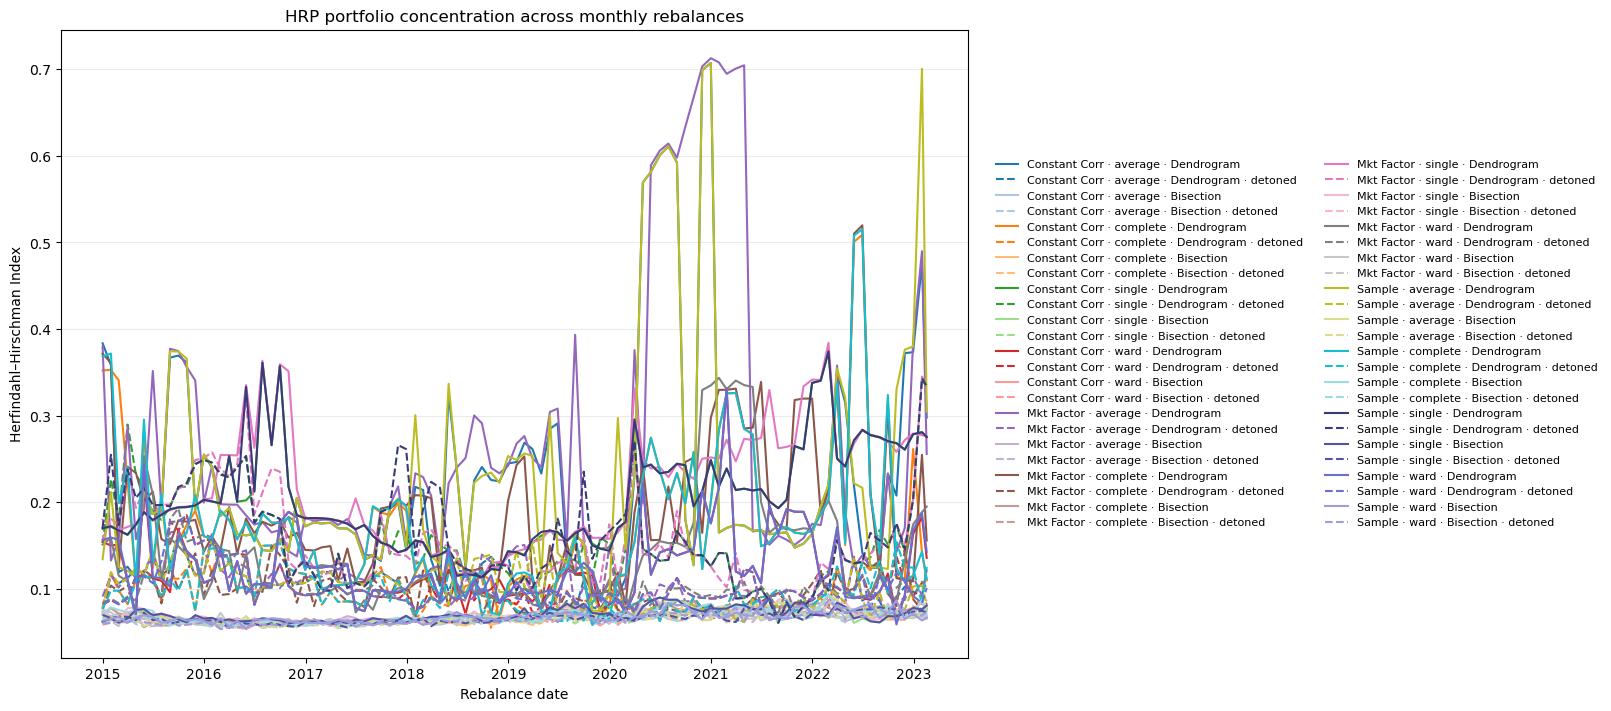

In [21]:
hrp_grid_hii = {}
hhi = lambda ptf: (ptf**2).sum()

for config in hrp_grid:
    hrp_grid_hii[config] = hrp_grid[config].apply(hhi, axis=1)

#Plotting HHI
groups = sorted({(cov, link, alloc) for cov, link, alloc, _ in hrp_grid_hii})
palette = plt.get_cmap("tab20").colors + plt.get_cmap("tab20b").colors
colors = dict(zip(groups, palette))

fig, ax = plt.subplots(figsize=(16, 7), layout="constrained")

for (cov, link, alloc, detoned), hhi in sorted(hrp_grid_hii.items()):
    method = "Bisection" if alloc == "recursive_bisection" else "Dendrogram"
    label = f"{cov.replace('_', ' ').title()} · {link} · {method}"

    ax.plot(
        hhi.index,
        hhi,
        color=colors[cov, link, alloc],
        linestyle="--" if detoned else "-",
        linewidth=1.5,
        label=label + (" · detoned" if detoned else ""),
    )

ax.set(
    title="HRP portfolio concentration across monthly rebalances",
    xlabel="Rebalance date",
    ylabel="Herfindahl–Hirschman Index",
)
ax.grid(axis="y", alpha=0.25)
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    ncol=2,
    frameon=False,
    fontsize=8,
)

plt.show()

## Comparisons


### ERC vs HRP — Robustness Against Estimator Choice

For the HRP strategy, to chose a rapresentative, I would prefer a detoned one (since it has a theoretical reason behind that I believe its really interesting and appropriate, given the concept of the allocation stratgy), and a variant where we use bisection as in Lopez paper (since, as shown above, they have generally less turnover wrt the dendogram iteration variant).
So let's plot something much more informative: the HHI evolution during time, so that we can chose something that in a stable way allocate weights more or less equally among assets


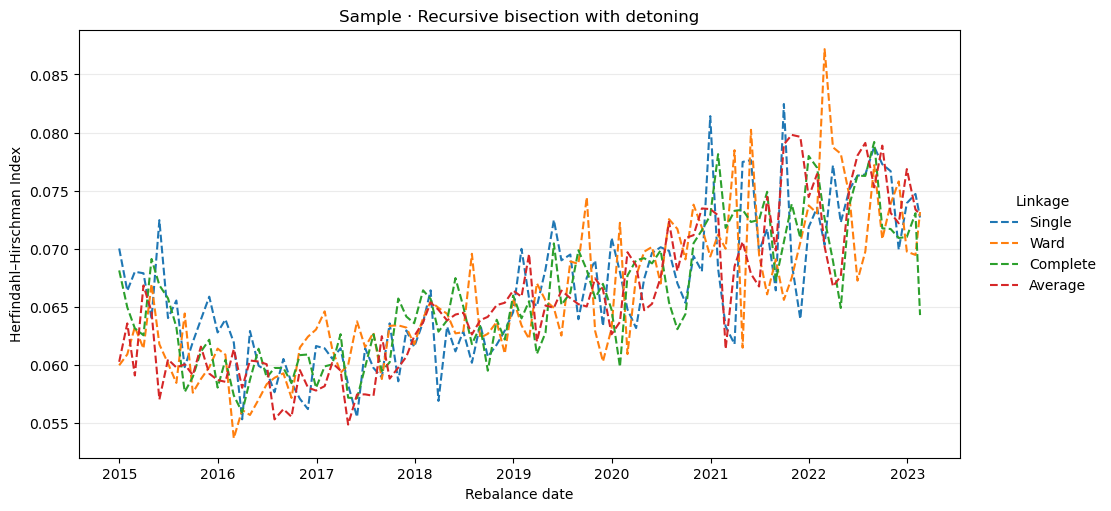

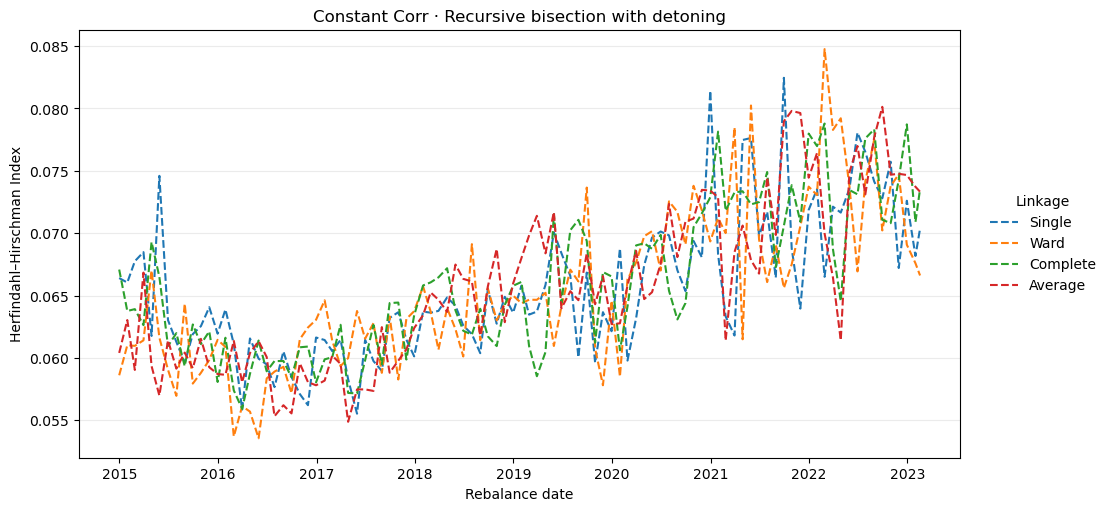

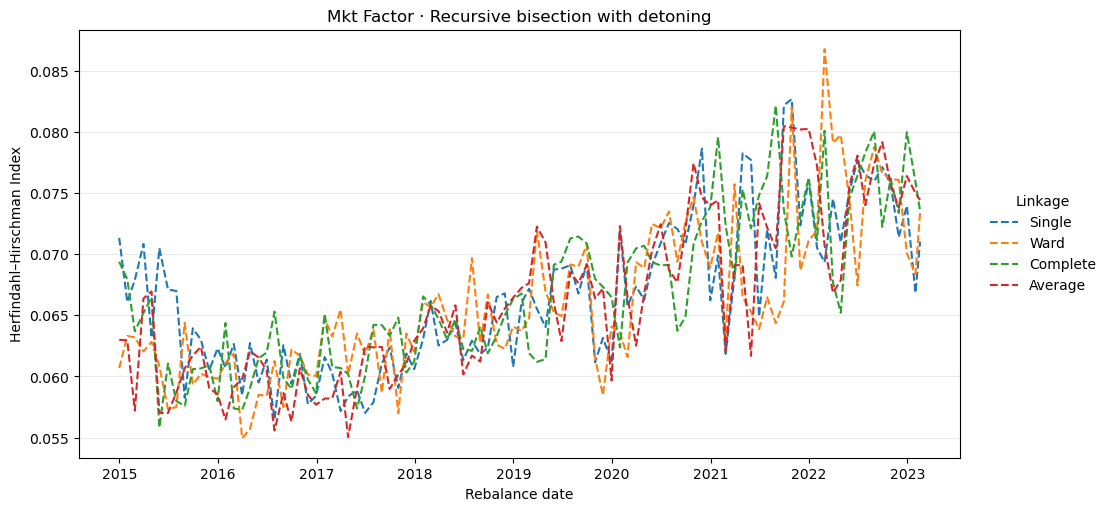

In [24]:
for cov in COV_KEYS:
    fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")

    for i, link in enumerate(LINK_GRID):
        config = (cov, link, "recursive_bisection", True)
        series = hrp_grid_hii[config]

        ax.plot(
            series.index,
            series,
            color=f"C{i}",
            linestyle="--",
            linewidth=1.5,
            label=link.capitalize(),
        )

    ax.set(
        title=f"{cov.replace('_', ' ').title()} · Recursive bisection with detoning",
        xlabel="Rebalance date",
        ylabel="Herfindahl–Hirschman Index",
    )
    ax.grid(axis="y", alpha=0.25)
    ax.legend(
        title="Linkage",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
    )

plt.show()

At this point, I will chose the Costant Correlation Target with Complete Linkage for the final comparison and the Complete Linkage, detoned, recursive bisection for stability wrt different covariance shrinkage

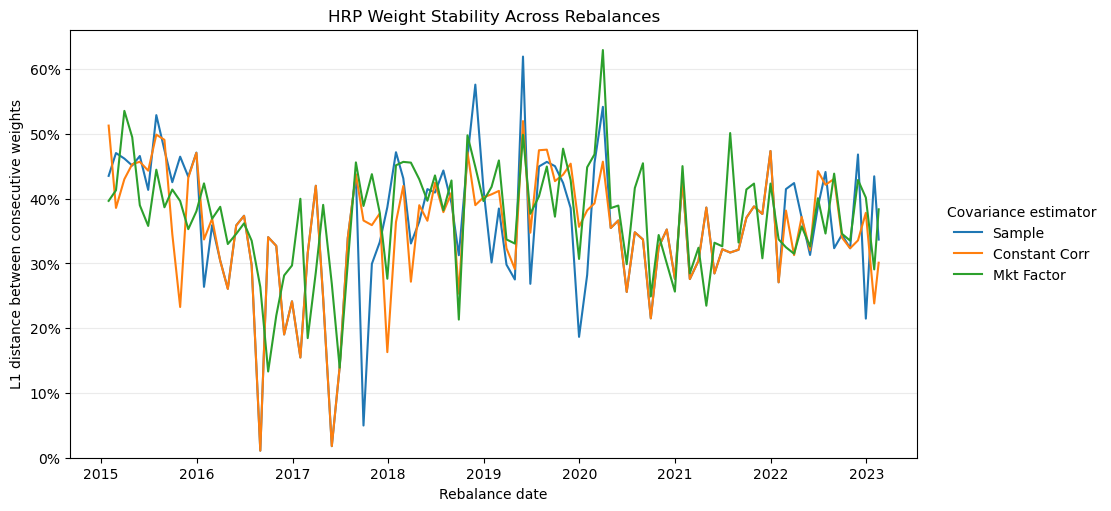

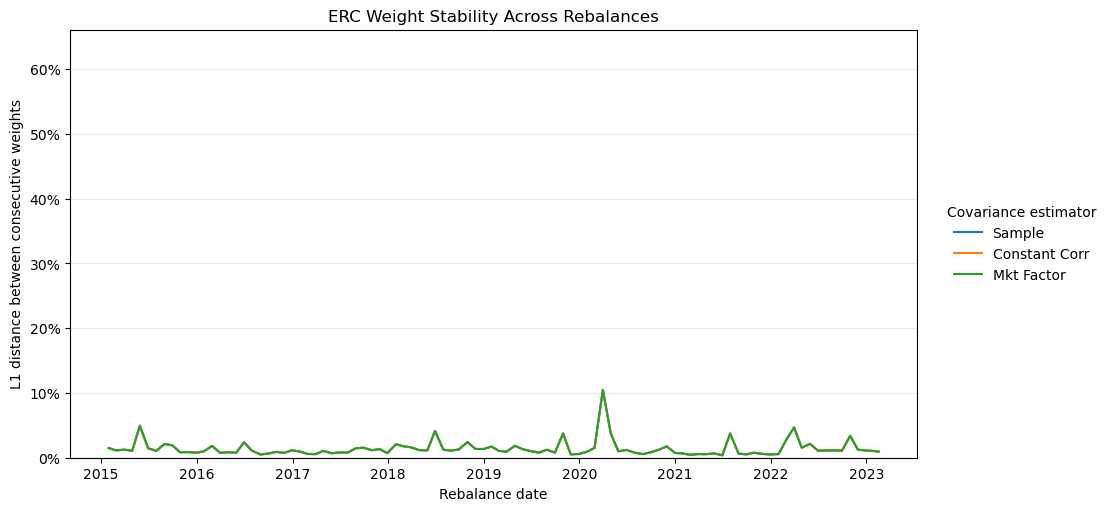

In [ ]:
selected_hrp = {}
stability_hrp = {}
stability_erc = {}

# Stability looked via the L1 distance of weights between rebalance dates    
for c in COV_KEYS:
    config = (c, "complete", "recursive_bisection", True)
    selected_hrp[c] = hrp_grid[config]
    stability_hrp[c] = hrp_grid[config].diff().abs().sum(axis=1)
    stability_erc[c] = erc_portfolios[c].diff().abs().sum(axis=1)

#Plotting
from matplotlib.ticker import PercentFormatter

results = {"HRP": stability_hrp, "ERC": stability_erc}
y_max = max(
    series.iloc[1:].max()
    for stability in results.values()
    for series in stability.values()
)

for strategy, stability in results.items():
    fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")

    for cov in COV_KEYS:
        series = stability[cov].iloc[1:]  # Skip the first date, which has no prior weights
        ax.plot(
            series.index,
            series,
            linewidth=1.5,
            label=cov.replace("_", " ").title(),
        )

    ax.set(
        title=f"{strategy} Weight Stability Across Rebalances",
        xlabel="Rebalance date",
        ylabel="L1 distance between consecutive weights",
        ylim=(0, y_max * 1.05),
    )
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.grid(axis="y", alpha=0.25)
    ax.legend(
        title="Covariance estimator",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
    )

plt.show()

### ERC vs HRP — performance, vol, drawdown, turnover


In [ ]:
config = ("constant_corr", "complete", "recursive_bisection", True)
hrp_strat = hrp_grid[config]
erc_strat = erc_portfolios["constant_corr"]

transaction_costs = 0.003 # i.e: 3 bsp

hrp_returns = backtest(hrp_strat, performance)
erc_returns = backtest(erc_strat, performance)

strat_stats = pd.DataFrame({"hrp": {}, "erc": {}}).T #T to have hrp, erc as rows

strat_stats["Total Returns"] = pd.Series({"hrp": hrp_returns.iloc[-1] - 1, "erc": erc_returns.iloc[-1] - 1})
strat_stats["Avg EWM 63d Vol"] = pd.Series({
    "hrp": hrp_returns.pct_change().ewm(span=63).std().mean() * np.sqrt(255),
    "erc": erc_returns.pct_change().ewm(span=63).std().mean() * np.sqrt(255)
})

rolling_max_hrp = hrp_returns.cummax()
rolling_max_erc = erc_returns.cummax()
strat_stats["Max DD"] = pd.Series({
    "hrp": min((hrp_returns - rolling_max_hrp)/rolling_max_hrp),
    "erc": min((erc_returns - rolling_max_erc)/rolling_max_erc)
})

print(strat_stats)

     Total Returns  Avg EWM 63d Vol     Max DD
hrp       1.797259        27.290226 -54.072424
erc       1.002795        17.778920 -39.503662
